# Wine Classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Load the dataset
wine = load_wine()
X = wine.data
y = wine.target

# 2. Split into Train (80%) and Test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Standardize features (Mean=0, Std=1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Part 1: Model Construction

In [2]:
# Create and train the base MLP model
base_mlp = MLPClassifier(random_state=42, max_iter=1000)
base_mlp.fit(X_train_scaled, y_train)

# Predict and evaluate
y_pred_base = base_mlp.predict(X_test_scaled)
print(f"Base Model Test Accuracy: {accuracy_score(y_test, y_pred_base):.4f}")

Base Model Test Accuracy: 0.9722


## Part 2: Explore Hyperparameter Space

In [3]:
# Define combinations of (hidden_layer_sizes)
layer_architectures = [
    (10,), (50,), (100,),
    (10, 10), (50, 50), (100, 100),
    (10, 10, 10), (50, 50, 50), (100, 100, 100)
]

results = []

for arch in layer_architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, random_state=42, max_iter=1000)
    mlp.fit(X_train_scaled, y_train)
    
    train_acc = mlp.score(X_train_scaled, y_train)
    test_acc = mlp.score(X_test_scaled, y_test)
    
    results.append({
        'architecture': str(arch),
        'layers': len(arch),
        'neurons_per_layer': arch[0],
        'train_accuracy': train_acc,
        'test_accuracy': test_acc,
        'model': mlp
    })

results_df = pd.DataFrame(results)
print(results_df[['architecture', 'train_accuracy', 'test_accuracy']])

      architecture  train_accuracy  test_accuracy
0            (10,)             1.0       1.000000
1            (50,)             1.0       0.944444
2           (100,)             1.0       0.972222
3         (10, 10)             1.0       0.972222
4         (50, 50)             1.0       0.972222
5       (100, 100)             1.0       0.972222
6     (10, 10, 10)             1.0       0.944444
7     (50, 50, 50)             1.0       0.972222
8  (100, 100, 100)             1.0       0.972222


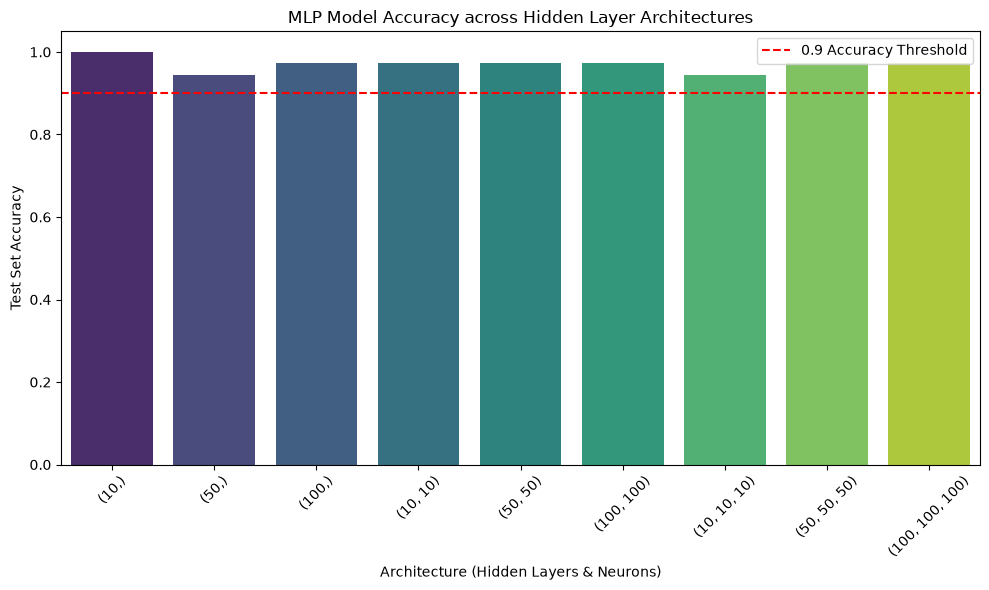

In [11]:
# Plot Accuracy Heatmap/Bar chart
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x='architecture', y='test_accuracy', hue='architecture', legend=False, palette='viridis')
plt.axhline(0.9, color='red', linestyle='--', label='0.9 Accuracy Threshold')
plt.xticks(rotation=45)
plt.title('MLP Model Accuracy across Hidden Layer Architectures')
plt.xlabel('Architecture (Hidden Layers & Neurons)')
plt.ylabel('Test Set Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Filter models with Test Accuracy > 0.9
high_perf_models = results_df[results_df['test_accuracy'] > 0.9]

for idx, row in high_perf_models.iterrows():
    arch = row['architecture']
    model = row['model']
    y_pred = model.predict(X_test_scaled)
    
    print(f"\n================ Model Architecture: {arch} ================")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report (Precision, Recall, F1-Score):")
    print(classification_report(y_test, y_pred, target_names=wine.target_names))


================ Model Architecture: (10,) ================
Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


================ Model Architecture: (50,) ================
Confusion Matrix:
[[12  0  0]
 [ 1 13  0]
 [ 0  1  9]]

Classification Report (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.93      0.93      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macr

### In the hyperperameter search, both the single layer (50,) and multi-layer (50,50) networks produced high accuracy scores (exceeding 0.9). I then chose the simpler model (10,) because it still achieves high accuracy scores but has fewer parameters and is less likely to overfit. 

### The precision measures the accuracy of the models ability to determine the type of wine and recall measures the count of wines it correctly guesses. 

### The confusion matrix and F-1 scores are strong across all three types of wine (class _0, class_1, class_2). The high scores show that the model was successful at identifying the type of wine and can accurately tell all three types apart. 

## Part 3: Apply Model

In [10]:
# 1. Define and fit your chosen final model (e.g., architecture (50,))
best_model = MLPClassifier(hidden_layer_sizes=(50,), random_state=42, max_iter=1000)
best_model.fit(X_train_scaled, y_train)

# 2. Load unknown samples
unknown_df = pd.read_csv('data/unknown_wine.csv')

# 3. Drop extra index/ID column if 14 columns are present
if unknown_df.shape[1] == 14:
    unknown_df = unknown_df.iloc[:, 1:]

# 4. Preprocess using the fitted scaler from Step 1
unknown_scaled = scaler.transform(unknown_df.values)

# 5. Predict classes and class probabilities
unknown_preds = best_model.predict(unknown_scaled)
unknown_probs = best_model.predict_proba(unknown_scaled)

# 6. Format into a clean DataFrame
probs_df = pd.DataFrame(
    unknown_probs, 
    columns=[f'Prob_{name}' for name in wine.target_names]
)
probs_df['Predicted_Class'] = [wine.target_names[p] for p in unknown_preds]

print(probs_df)

     Prob_class_0  Prob_class_1   Prob_class_2 Predicted_Class
0             1.0           0.0   0.000000e+00         class_0
1             1.0           0.0   0.000000e+00         class_0
2             1.0           0.0   0.000000e+00         class_0
3             1.0           0.0   0.000000e+00         class_0
4             1.0           0.0   0.000000e+00         class_0
..            ...           ...            ...             ...
173           1.0           0.0   0.000000e+00         class_0
174           1.0           0.0   0.000000e+00         class_0
175           1.0           0.0  1.807766e-316         class_0
176           1.0           0.0   0.000000e+00         class_0
177           1.0           0.0   0.000000e+00         class_0

[178 rows x 4 columns]


### I used scikit-learn's predict_proba (predict probability) function. This function provides a percentage score on how confident the model is for each class of wine instead of just guesssing the type of wine. High probability is considered 85% (0.85) or higher and means that the model is confident about which class the wine belongs to based on the features clearly matching that type of wine. Low or split probability would be anything under 85% and means that the wine has features that overlap between two types of wine making the model less confident about the correct wine grouping. 